# Simulation: Source Spike with Propagation

Explain simulation please

## 📦 Imports

In [1]:
import mindmap as mm 
import pyvista as pv
import pywt
import numpy as np
import mne
import seaborn as sns
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `eeg`: EEG template
- `fwd`: Forward solution
- `sc`: Structural connectome
- `parc`: Parcellation
- `cras`: Transformation (MRI -> RAS)
- `white`: Inner cortical surface
- `hmodel`: Head conductor model 
- `cst`: Connectome spectrum transform
- `ctx`: Cortical mask

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id (position in list SUBS)

In [2]:
############### Parameters #################
fconfig = "../../papers/simf/configuration.yml"
sub     = 0
############################################

# configuration
reader = mm.io.dataset_reader(fconfig)

# data
data = reader(sub, "eeg", "fwd", "sc", "parc", "cras", "white", "bem", "cst", "ctx")

# forward matrix
A = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
A = A["sol"]["data"]

# region label of dipoles
regions = data["parc"].get_clut()["Label name"].values                                                  # region ids
pos     = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels  = data["parc"].label_points(pos)                                                                # dipole labels

# eeg meta-data
sfreq = data["eeg"].info["sfreq"]
time  = data["eeg"].times

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- ctx
- white
- bem
- sc
- fwd
- cras
- parc
- eeg
- cst
Missing objects:


## Simulation

#### ⚙️ **<font color=green>Generate simulation</font>**
🛠️ **<font color=violet>Source Spike</font>**:
- `duration`: duration of the simulation
- `amplitude`: maximum amplitude of spike
- `width`: duration of the spike
- `location`: location of the source spike given by a brain region

🛠️ **<font color=violet>Spike Propagation</font>**:
- `conductance`: Propagation weight [0-1]
- `delay`: Propagation delay in [ms]

🛠️ **<font color=violet>Noise Generation</font>**:
- `target_snr`: Maximum EEG SNR in [dB] expcted
- `noise_ratio`: Ratio [0-1] between brain noise and EEG electrical noise.

In [3]:

########################### Parameters #############################
# Source Spike
duration  = 1000
amplitude = 1e-8
width     = 100
location  = "random"

# Spike Propagation
conductance     = 0.25
conductance_std = 0  
delay           = 30
delay_std       = 0

# Noise Generation
target_snr  = 20
noise_ratio = 0.9
######################################################################

sim = mm.utils.Simulation(data["fwd"], data["sc"], duration=duration, parcellation=data["parc"], cras=data["cras"])

sim.set_spike(location, duration=width, amplitude=amplitude)
sim.run_propagation(conductance=conductance, delay=delay)
#sim.run_propagation2(n_hops=2, conductance=conductance, delay=delay, delay_std=delay_std)
sim.set_noise(target_snr=target_snr, noise_ratio=noise_ratio)
sim.run_eeg(data["eeg"].info)

sim.summary()

SIMULATION SUMMARY
Source Space info:
- Number of dipoles: 4961
- Parcellation: available
- Noise type: pink
- Noise contribution: 0.9
EEG info:
- Number of electrodes: 203
- Target SNR: 20 [dB]
- Noise type: white
- Noise contribution: 0.09999999999999998
Window info
- Duration: 1.0 [s]
- Sampling rate: 250
Spike info:
- Location: ctx-rh-rostralmiddlefrontal_6
- Onset: 502.00803212851395 [ms]
- Amplitude: 1e-08 [A]
- Duration: 100 [ms]
- Maximum: 0.5341365461847389 [ms]
Propagation info:
- Conductance: 0.25
- Delay: 30 [ms]


#### 🌟 Visualize Simulation

🛠️ **<font color=violet>Simulation plots</font>**:
- `plot`: Plot type. Can be one of ["spike", "brain", "eeg", "noise"]

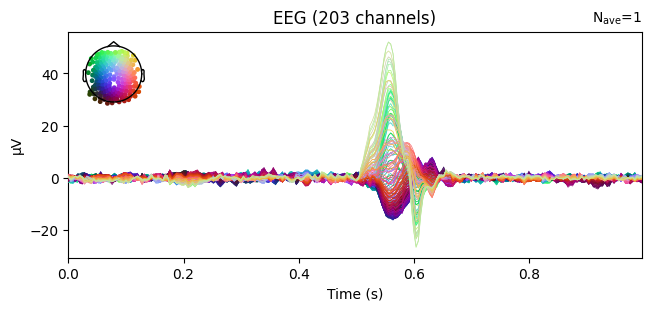

In [4]:
########################### Parameters #############################
# choose plot ("spike", "brain", "eeg", "noise")
plot = "eeg"
####################################################################

if plot == "spike":
    _ = sim.plot_spike(noise=True)
elif plot == "brain":
    sim.plot_brain(noise=True).show()
elif plot == "eeg":
    sim.plot_eeg(noise=True)
elif plot == "noise":
    sim.plot_noise()
else:
    raise ValueError("Unknown plot type")

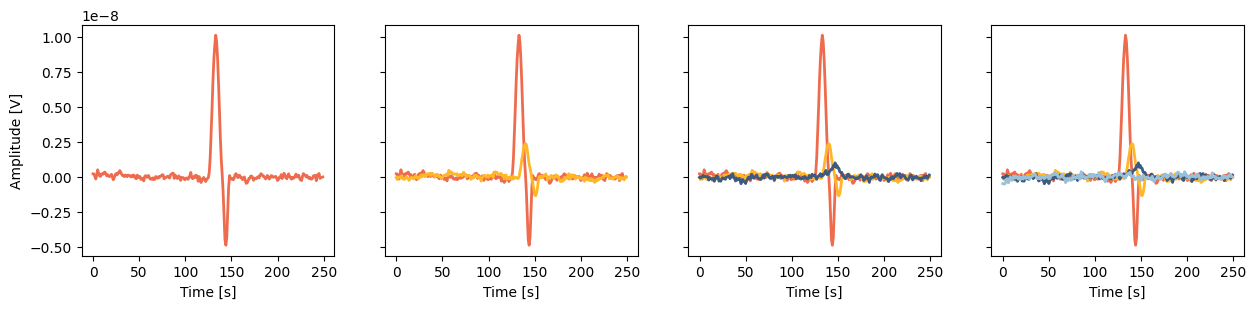

In [5]:
mm.viz.plot_hops(sim)

#### 🌟 Visualize peak phase and half rising phase


In [6]:
time_hrp  = mm.utils.eeg_rising_phase(sim.get_eeg(), 0.5)
time_peak = mm.utils.eeg_rising_phase(sim.get_eeg(), 1)
print(f"Half rising phase: {time_hrp}")
print(f"Peak rising phase: {time_peak}")

activity = sim.get_activity()
activity.data = np.abs(activity.data)
mm.viz.plot_brain(sim.fwd["src"], sim.get_activity(), absolute=True).show()


Half rising phase: 0.536
Peak rising phase: 0.556


Widget(value='<iframe src="http://localhost:37569/index.html?ui=P_0x707b9fdd7910_0&reconnect=auto" class="pyvi…

In [7]:
activity = sim.get_activity().copy()
activity = activity.crop(0.5, 0.62)

mm.viz.brain_gif(data["fwd"]["src"], activity.data, "simu_example.gif", 
    camera_position = "yz", 
    zoom            = 1.5,
    fps             = 5
)

In [ ]:
# data
spike   = sim.get_spike(noise=False)
conn    = sim.sc

# starting
visited = np.zeros(len(conn), dtype=bool)
visited[sim.loc_ids] = True



np.int64(11)

In [36]:
def diffuse_time_series(adj_matrix, time_series, start_node, n_iters=10, alpha=0.5):
    N = adj_matrix.shape[0]
    T = len(time_series)
    X = np.zeros((N,T))

    X[start_node] = time_series

    A = adj_matrix.copy()
    A = A / A.sum(axis=1, keepdims=True)

    for _ in range(n_iters):
        X_new = A @ X   # each node gets the average time series from neighbors
        X = alpha * X_new + (1-alpha) * X   # update with mixing factor

    return X

test = diffuse_time_series(conn, spike, start_node=sim.loc_ids)

In [37]:
sim.act.data = test 
sim.plot_brain(noise=False).show()

Widget(value='<iframe src="http://localhost:32799/index.html?ui=P_0x7dd83ed05610_8&reconnect=auto" class="pyvi…

In [129]:
spike = sim.spike
conn  = sim.sc 
n_iter = 2

dw = 0.05
dw_std = 0
delay = 100
delay_std = 0


N = len(conn)
T = len(spike)
X = np.zeros((N,T))

visited        = [sim.loc_ids]
X[visited[-1]] = spike

for _ in range(n_iter):
    last_visited = visited[-1]
    new_visited  = set()

    for node in last_visited:
        neighbors = np.argwhere(conn[node] == 1).squeeze()

        for v in visited:
            neighbors = list(set(neighbors)-set(v))
        new_visited = new_visited.union(set(neighbors))

        if len(neighbors) > 0:
            weights = np.random.normal(dw, dw_std, len(neighbors))
            delays  = np.random.normal(delay, delay_std, len(neighbors))
            delays  = delays/1000 * 250
            new_X   = np.array([w*np.roll(X[node,:], int(d)) for w, d in zip(weights, delays)])
            X[neighbors] += new_X
    
    visited.append(list(new_visited))

In [130]:
sim.act.data = X
sim.plot_brain(noise=False).show()

Widget(value='<iframe src="http://localhost:32799/index.html?ui=P_0x7dd8367bf790_35&reconnect=auto" class="pyv…

In [109]:
neighbors

[]